In [41]:
import pandas as pd 
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split,cross_val_score, StratifiedKFold
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from optbinning import BinningProcess
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_curve, precision_score, recall_score
from sklearn.base import clone
import joblib
from datetime import date

# EDA

In [2]:
ROOT = Path.cwd().parent
DATA = ROOT / "data"

In [3]:
df = pd.read_csv(DATA / "model_data.csv", index_col = 0)
df.shape

(105000, 11)

In [4]:
df.head()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
138986,0,0.000000,49,0,0.127227,5163.0,5,0,0,0,0.0
63965,0,0.033105,37,0,0.423063,2800.0,4,0,1,0,1.0
46078,0,0.007948,39,0,0.685663,3333.0,11,0,1,0,0.0
83031,0,0.576297,57,0,0.320077,15161.0,14,0,4,0,0.0
11185,0,0.623724,35,0,0.534226,6500.0,9,0,3,0,1.0


In [5]:
df.info()

<class 'pandas.DataFrame'>
Index: 105000 entries, 138986 to 80531
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      105000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  105000 non-null  float64
 2   age                                   105000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  105000 non-null  int64  
 4   DebtRatio                             105000 non-null  float64
 5   MonthlyIncome                         84277 non-null   float64
 6   NumberOfOpenCreditLinesAndLoans       105000 non-null  int64  
 7   NumberOfTimes90DaysLate               105000 non-null  int64  
 8   NumberRealEstateLoansOrLines          105000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  105000 non-null  int64  
 10  NumberOfDependents                    102279 non-null  float64
dtypes: float64(4

In [6]:
df.isna().mean().sort_values(ascending=False)

MonthlyIncome                           0.197362
NumberOfDependents                      0.025914
SeriousDlqin2yrs                        0.000000
age                                     0.000000
RevolvingUtilizationOfUnsecuredLines    0.000000
DebtRatio                               0.000000
NumberOfTime30-59DaysPastDueNotWorse    0.000000
NumberOfOpenCreditLinesAndLoans         0.000000
NumberOfTimes90DaysLate                 0.000000
NumberRealEstateLoansOrLines            0.000000
NumberOfTime60-89DaysPastDueNotWorse    0.000000
dtype: float64

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,105000.0,0.066838,0.249743,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,105000.0,6.482739,267.781319,0.0,0.029642,0.153553,0.560096,50708.0
age,105000.0,52.277657,14.760952,21.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,105000.0,0.415752,4.125424,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,105000.0,355.053748,2200.062016,0.0,0.175949,0.367554,0.861211,329664.0
MonthlyIncome,84277.0,6613.049385,11166.674413,0.0,3400.000000,5382.000000,8227.000000,1794060.0
NumberOfOpenCreditLinesAndLoans,105000.0,8.466371,5.149922,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,105000.0,0.260752,4.100944,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,105000.0,1.019343,1.128383,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,105000.0,0.234552,4.086610,0.0,0.000000,0.000000,0.000000,98.0


In [8]:
for col in ["NumberOfTime30-59DaysPastDueNotWorse",
            "NumberOfTime60-89DaysPastDueNotWorse",
            "NumberOfTimes90DaysLate"]:
    print(col, df[col].value_counts().sort_index().tail(5).to_dict())

NumberOfTime30-59DaysPastDueNotWorse {11: 1, 12: 1, 13: 1, 96: 1, 98: 181}
NumberOfTime60-89DaysPastDueNotWorse {6: 11, 7: 6, 11: 1, 96: 1, 98: 181}
NumberOfTimes90DaysLate {14: 1, 15: 2, 17: 1, 96: 1, 98: 181}


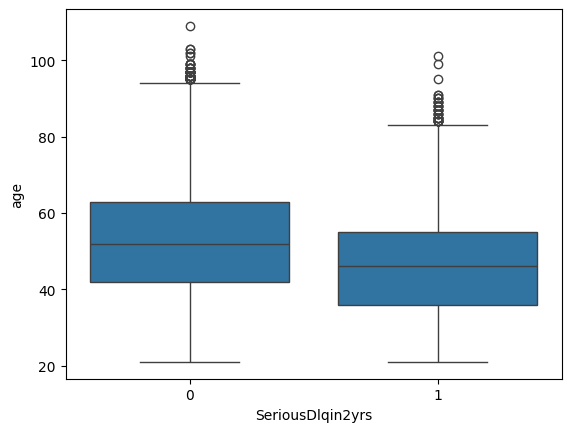

In [9]:
sns.boxplot(data=df, x="SeriousDlqin2yrs", y="age")
plt.show()

## Dataset Features

| Feature | Description |
|---|---|
| `SeriousDlqin2yrs` | **Target.** 1 if the borrower experienced 90+ days past due delinquency within 2 years, 0 otherwise |
| `RevolvingUtilizationOfUnsecuredLines` | Share of credit card and personal credit line limits currently used (balance / limit) |
| `age` | Borrower's age in years |
| `NumberOfTime30-59DaysPastDueNotWorse` | Number of times 30–59 days past due in the last 2 years |
| `NumberOfTime60-89DaysPastDueNotWorse` | Number of times 60–89 days past due in the last 2 years |
| `NumberOfTimes90DaysLate` | Number of times 90+ days past due |
| `DebtRatio` | Monthly debt payments, alimony and living costs divided by monthly gross income |
| `MonthlyIncome` | Monthly income (~20% missing) |
| `NumberOfOpenCreditLinesAndLoans` | Number of open loans (e.g. car loan, mortgage) and credit lines (e.g. credit cards) |
| `NumberRealEstateLoansOrLines` | Number of mortgage and real estate loans, including home equity lines of credit |
| `NumberOfDependents` | Number of dependents in the family, excluding the borrower (~2.6% missing) |

**Data quality notes:**
- Values 96 and 98 in past-due columns are special codes, not real counts
- `RevolvingUtilizationOfUnsecuredLines` and `DebtRatio` contain extreme outliers
- Target is imbalanced: ~6.7% defaults

In [10]:
TARGET = "SeriousDlqin2yrs"

In [11]:
X = df.drop(columns=TARGET)
y = df[TARGET]

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [13]:
PAST_DUE = ["NumberOfTime30-59DaysPastDueNotWorse","NumberOfTime60-89DaysPastDueNotWorse","NumberOfTimes90DaysLate"]

In [14]:
def fit_cleaner(X):
    X = X.copy()
    X[PAST_DUE] = X[PAST_DUE].replace({96: np.nan, 98: np.nan})
    return {
        "past_due_median": X[PAST_DUE].median(),
        "income_median": X["MonthlyIncome"].median(),
        "revolving_cap": X["RevolvingUtilizationOfUnsecuredLines"].quantile(0.99),
        "debt_cap": X["DebtRatio"].quantile(0.99),
    }

In [15]:
def clean(X,params):
    X = X.copy()
    X[PAST_DUE] = X[PAST_DUE].replace({96: np.nan, 98: np.nan})
    X[PAST_DUE] = X[PAST_DUE].fillna(params["past_due_median"])
    X["IncomeMissing"] = X["MonthlyIncome"].isna().astype(int)
    X["MonthlyIncome"] = X["MonthlyIncome"].fillna(params["income_median"])
    X["NumberOfDependents"] = X["NumberOfDependents"].fillna(0)
    X["RevolvingUtilizationOfUnsecuredLines"] = X["RevolvingUtilizationOfUnsecuredLines"].clip(upper=params["revolving_cap"])
    X["DebtRatio"] = X["DebtRatio"].clip(upper=params["debt_cap"])
    X["age"] = X["age"].clip(lower=18)
    return X 

In [16]:
params = fit_cleaner(X_train)

In [17]:
X_train_clean = clean(X_train, params)
X_test_clean = clean(X_test, params)

In [18]:
baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000),
)

In [19]:
baseline.fit(X_train_clean, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some 

In [20]:
proba_base = baseline.predict_proba(X_test_clean)[:, 1]
auc_base = roc_auc_score(y_test, proba_base)

In [21]:
print(f"ROC-AUC: {auc_base:.4f}")
print(f"Gini: {2 * auc_base - 1:.4f}")

ROC-AUC: 0.8588
Gini: 0.7176


In [22]:
features = list(X_train_clean.columns)

In [23]:
binning = BinningProcess(
    variable_names=features,
    selection_criteria={"iv": {"min": 0.02}},
    min_prebin_size=0.02,   # группы могут быть мельче (от 2% клиентов)
    max_n_bins=10,          # до 10 групп на признак
)

In [24]:
woe_model = Pipeline ([
    ("binning", binning), 
    ("lr", LogisticRegression(max_iter=1000)),
])

In [25]:
woe_model.fit(X_train_clean, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('binning', ...), ('lr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,variable_names,"['RevolvingUtilizationOfUnsecuredLines', 'age', ...]"
,max_n_prebins,20
,min_prebin_size,0.02
,min_n_bins,None
,max_n_bins,10
,min_bin_size,None
,max_bin_size,None


In [26]:
proba_woe = woe_model.predict_proba(X_test_clean)[:, 1]
auc_woe = roc_auc_score(y_test, proba_woe)

In [27]:
print(f"ROC-AUC: {auc_woe:.4f}")
print(f"Gini: {2 * auc_woe - 1:.4f}")

ROC-AUC: 0.8622
Gini: 0.7244


In [28]:
special = {"special_codes": [96,98]}

In [29]:
woe_final = Pipeline([
    ("binning", BinningProcess(
        variable_names=list(X_train.columns),
        selection_criteria={"iv": {"min": 0.02}},
        min_prebin_size=0.02, 
        max_n_bins=10,
        binning_fit_params={col: special for col in PAST_DUE},
    )),
    ("lr", LogisticRegression(max_iter=1000)),
])

In [30]:
woe_final.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('binning', ...), ('lr', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,variable_names,"['RevolvingUtilizationOfUnsecuredLines', 'age', ...]"
,max_n_prebins,20
,min_prebin_size,0.02
,min_n_bins,None
,max_n_bins,10
,min_bin_size,None
,max_bin_size,None


In [31]:
proba_final = woe_final.predict_proba(X_test)[:, 1]
auc_final = roc_auc_score(y_test, proba_final)
fpr, tpr, _ = roc_curve(y_test, proba_final)

print(f"ROC-AUC: {auc_final:.4f}")
print(f"Gini:    {2 * auc_final - 1:.4f}")
print(f"KS:      {(tpr - fpr).max():.4f}")

ROC-AUC: 0.8630
Gini:    0.7261
KS:      0.5676


In [32]:
bp = woe_final.named_steps["binning"]
bp.get_binned_variable("NumberOfTimes90DaysLate").binning_table.build()

,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.50)",79261,0.943583,75614,3647,0.046013,0.395355,0.124541,0.015467
1,"[0.50, inf)",4590,0.054643,2707,1883,0.410240,-2.273407,0.684016,0.070831
2,Special,149,0.001774,65,84,0.563758,-2.892811,0.040885,0.003848
3,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,84000,1.000000,78386,5614,0.066833,,0.849443,0.090146


In [38]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(clone(woe_final), X, y, cv=cv, scoring="roc_auc")
print(f"CV ROC-AUC: {scores.mean():.4f} ± {scores.std():.4f}")

CV ROC-AUC: 0.8563 ± 0.0071


In [40]:
rows = []
for t in [0.05, 0.1, 0.15, 0.2, 0.3, 0.5]:
    pred = (proba_final >= t).astype(int)
    rows.append({
        "threshold": t,
        "reject_rate": pred.mean(),
        "recall": recall_score(y_test, pred),
        "precision": precision_score(y_test, pred),
    })

pd.DataFrame(rows).round(3)


,threshold,reject_rate,recall,precision
0,0.05,0.301,0.818,0.182
1,0.10,0.154,0.652,0.284
2,0.15,0.096,0.535,0.372
3,0.20,0.074,0.460,0.418
4,0.30,0.047,0.343,0.488
5,0.50,0.021,0.184,0.586


In [42]:
THRESHOLD = 0.10

In [44]:
artifact = {
    "model": woe_final,
    "threshold": THRESHOLD,
    "features": list(X_train.columns),
    "version": "v1",
    "trained_at": str(date.today()),
    "metrics": {
        "test_roc_auc": round(auc_final, 4),
        "cv_roc_auc": round(scores.mean(), 4),
    },
}

(ROOT / "models").mkdir(exist_ok=True)
joblib.dump(artifact, ROOT / "models" / "model_v1.joblib")

['D:\\Projects\\credit-scoring-pipeline\\models\\model_v1.joblib']

Лучший C: {'lr__C': 0.1}
Лучший CV ROC-AUC: 0.8564


,param_lr__C,mean_test_score,std_test_score
0,0.01,0.8563,0.0069
1,0.10,0.8564,0.0071
2,1.00,0.8563,0.0071
3,10.00,0.8563,0.0071
4,100.00,0.8563,0.0071
